# 01 – Load and explore
**Goal:** understand the dataset and flag data-quality problems *before* modelling.
Write what you see and why you decide things in `docs/decisions_log.md` as you go.

In [1]:
  %pip install numpy pandas matplotlib scikit-learn

You should consider upgrading via the '/usr/local/bin/python3 -m pip install --upgrade pip' command.
Note: you may need to restart the kernel to use updated packages.


In [2]:
import sys; sys.path.insert(0, "../src")
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from ev_energy import load_data, quality_report, TARGET

df = load_data("../data/raw/ev_trip_energy.csv")
print(df.shape)
df.head()

(10151, 14)


,energy_kwh,vehicle_id,distance_km,hour,weekday,lon,lat,speed_raw,current_a,voltage_v,temp_max_c,temp_min_c,duration_min,avg_speed_kmh
0,0.672,1,6,10.333333,4,121.497948,31.281574,246.000000,2.583348,308.283333,31.000000,30.833333,13,27.692308
1,0.896,1,6,16.000000,4,121.587564,31.256070,393.714286,2.985729,304.485714,29.000000,28.000000,18,20.000000
2,1.344,1,7,16.090909,2,121.576968,31.262034,192.000000,2.354560,308.463636,31.272727,30.000000,21,20.000000
3,1.344,1,8,19.000000,5,121.549709,31.257796,369.240000,1.540015,308.060000,30.000000,30.000000,16,30.000000
4,0.896,1,6,14.166667,6,121.582280,31.215030,413.450617,9.659892,304.473457,28.000000,28.000000,129,2.790698


## 1. Structure, types, missing values, duplicates

In [3]:
print(df.dtypes)
print("missing:", int(df.isna().sum().sum()), "| duplicate rows:", int(df.duplicated().sum()))
print("vehicles:", df.vehicle_id.nunique(), "| trips per vehicle (min/median/max):",
      df.vehicle_id.value_counts().agg(["min","median","max"]).tolist())
df.describe().T

energy_kwh       float64
vehicle_id         int64
distance_km        int64
hour             float64
weekday            int64
lon              float64
lat              float64
speed_raw        float64
current_a        float64
voltage_v        float64
temp_max_c       float64
temp_min_c       float64
duration_min       int64
avg_speed_kmh    float64
dtype: object
missing: 0 | duplicate rows: 0
vehicles: 50 | trips per vehicle (min/median/max): [38.0, 204.5, 372.0]


,count,mean,std,min,25%,50%,75%,max
energy_kwh,10151.0,3.952449,2.838899,0.672000,1.792000,3.136000,5.152000,20.832000
vehicle_id,10151.0,23.725544,13.812557,1.000000,12.000000,23.000000,35.000000,50.000000
distance_km,10151.0,18.514728,13.073244,6.000000,8.000000,14.000000,25.000000,97.000000
hour,10151.0,13.683350,5.055271,0.000000,10.000000,14.047619,17.583333,23.000000
weekday,10151.0,3.207270,1.993929,0.000000,1.000000,3.000000,5.000000,6.000000
lon,10151.0,121.344636,2.412927,48.156145,121.229993,121.353008,121.441564,343.178931
lat,10151.0,31.192769,6.820456,-645.073007,31.204136,31.286416,31.351568,114.008944
speed_raw,10151.0,62.162325,94.236249,0.000000,11.322876,31.833333,67.648148,930.642857
current_a,10151.0,4.046153,5.753897,-20.799985,0.876345,2.172015,4.952193,85.233349
voltage_v,10151.0,305.319799,3.509373,282.604167,303.645369,305.403175,307.636825,435.321429


## 2. Plausibility checks (flag, don't delete)

In [4]:
quality_report(df)

,missing,outside_range,range,min,max
column,,,,,
energy_kwh,0,0,"[0, 60]",0.672000,20.832000
distance_km,0,0,"[0, 300]",6.000000,97.000000
hour,0,0,"[0, 24]",0.000000,23.000000
weekday,0,0,"[0, 6]",0.000000,6.000000
speed_raw,0,1009,"[0, 150]",0.000000,930.642857
voltage_v,0,1,"[250, 400]",282.604167,435.321429
temp_max_c,0,0,"[-30, 60]",-2.039216,33.859223
temp_min_c,0,0,"[-30, 60]",-3.225806,31.777778
duration_min,0,0,"[1, 600]",4.000000,393.000000


**Things to investigate and explain in the report**
- `speed_raw` reaches ~930 – is it really km/h? Compare with `avg_speed_kmh = distance / duration` (below).
- Voltage, latitude, longitude have impossible extremes – sensor glitches or real?
- Decide per column: remove, cap, or keep (and justify).

count    10151.000000
mean         3.942474
std          6.885757
min          0.000000
25%          0.978995
50%          1.997436
75%          4.461287
max        237.399368
dtype: float64


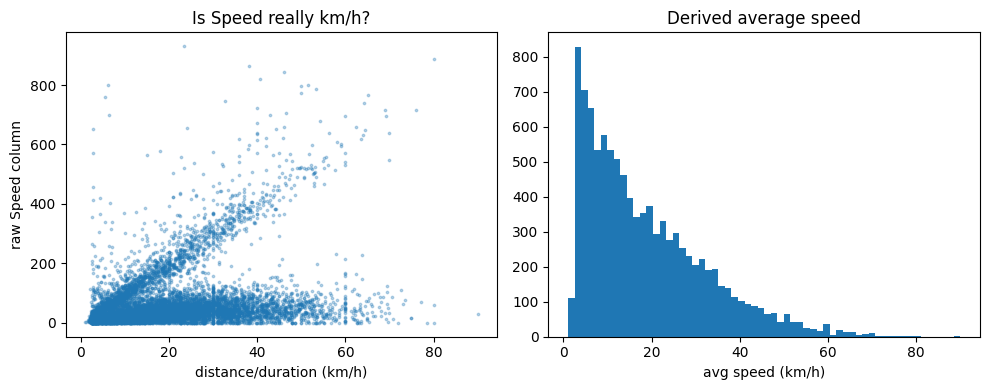

In [5]:
ratio = df.speed_raw / df.avg_speed_kmh
print(ratio.describe())
fig, ax = plt.subplots(1, 2, figsize=(10, 4))
ax[0].scatter(df.avg_speed_kmh, df.speed_raw, s=3, alpha=.3)
ax[0].set(xlabel="distance/duration (km/h)", ylabel="raw Speed column", title="Is Speed really km/h?")
ax[1].hist(df.avg_speed_kmh, bins=60); ax[1].set(xlabel="avg speed (km/h)", title="Derived average speed")
plt.tight_layout(); plt.savefig("../figures/speed_check.png", dpi=150); plt.show()

## 3. Target variable

unique values: 83
smallest steps between values: [0.224 0.448 0.672 0.896]


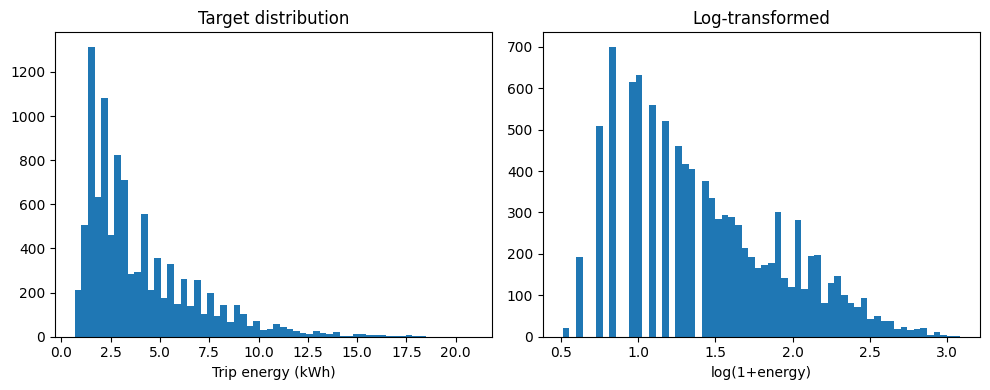

In [6]:
e = df[TARGET]
print("unique values:", e.nunique())
print("smallest steps between values:", np.unique(np.diff(np.sort(e.unique())).round(4))[:5])
fig, ax = plt.subplots(1, 2, figsize=(10, 4))
ax[0].hist(e, bins=60); ax[0].set(xlabel="Trip energy (kWh)", title="Target distribution")
ax[1].hist(np.log1p(e), bins=60); ax[1].set(xlabel="log(1+energy)", title="Log-transformed")
plt.tight_layout(); plt.savefig("../figures/target_dist.png", dpi=150); plt.show()

**Observation to discuss:** the target takes only a few dozen discrete values (multiples of 0.224 kWh).
This limits the best achievable error and R² – mention it under limitations, and check how the dataset describes it
(see the *Data Replication Explanatory File*).

## 4. Relationships with energy

voltage_v       -0.107
hour            -0.070
weekday          0.012
temp_min_c       0.037
speed_raw        0.050
temp_max_c       0.060
current_a        0.189
duration_min     0.298
avg_speed_kmh    0.421
distance_km      0.916
Name: energy_kwh, dtype: float64


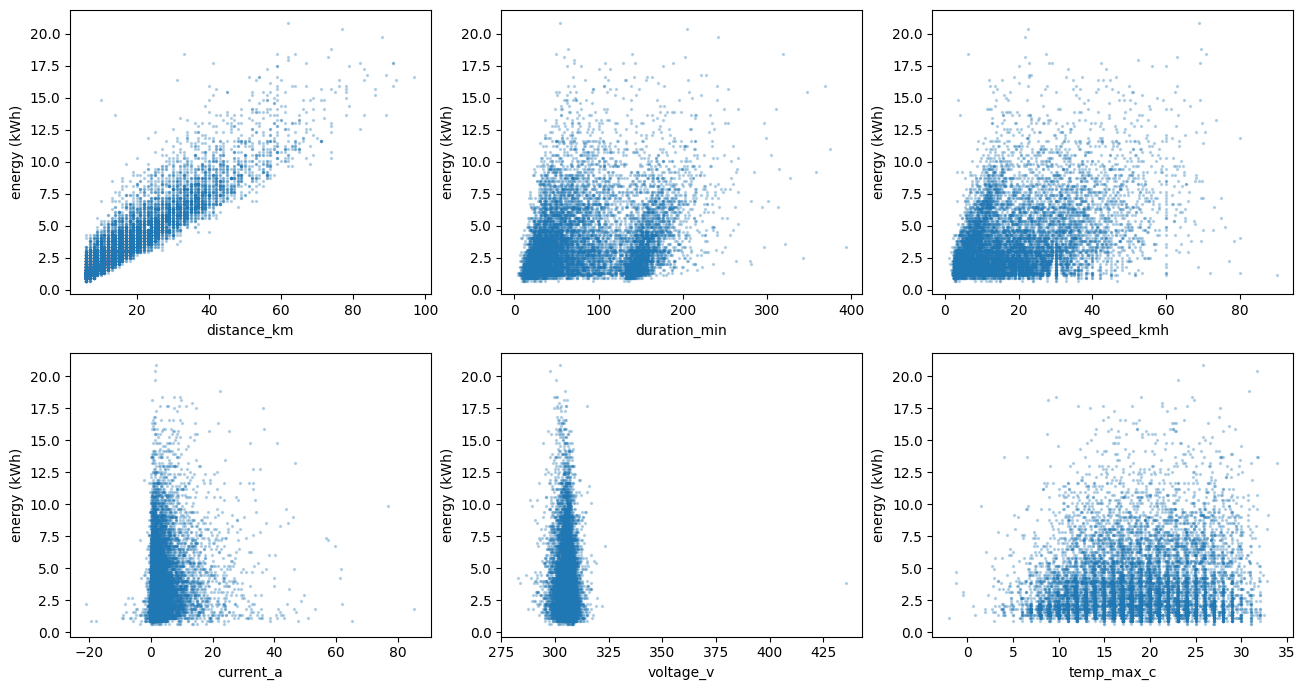

In [7]:
num = ["distance_km","duration_min","avg_speed_kmh","speed_raw","current_a","voltage_v","temp_max_c","temp_min_c","hour","weekday"]
corr = df[[TARGET]+num].corr(method="spearman")[TARGET].drop(TARGET).sort_values()
print(corr.round(3))
fig, axs = plt.subplots(2, 3, figsize=(13, 7))
for ax, c in zip(axs.ravel(), ["distance_km","duration_min","avg_speed_kmh","current_a","voltage_v","temp_max_c"]):
    ax.scatter(df[c], df[TARGET], s=2, alpha=.25); ax.set(xlabel=c, ylabel="energy (kWh)")
plt.tight_layout(); plt.savefig("../figures/energy_vs_features.png", dpi=150); plt.show()

## 5. Leakage and multicollinearity – think before modelling
- `current_a` and `voltage_v` are measured *during* the trip, so they are not known in advance. Keep your *trip-only* vs *trip + electrical* comparison and say so in the report.
- Max/min cell temperature and distance/duration/speed are strongly related. Check the correlation matrix.

In [8]:
df[num].corr().round(2)

,distance_km,duration_min,avg_speed_kmh,speed_raw,current_a,voltage_v,temp_max_c,temp_min_c,hour,weekday
distance_km,1.00,0.29,0.43,0.05,0.06,-0.03,0.15,0.13,-0.08,0.03
duration_min,0.29,1.00,-0.58,-0.29,-0.30,-0.02,-0.02,-0.02,0.07,-0.00
avg_speed_kmh,0.43,-0.58,1.00,0.34,0.36,-0.04,0.15,0.13,-0.15,0.00
speed_raw,0.05,-0.29,0.34,1.00,0.73,-0.17,0.07,0.07,-0.04,0.00
current_a,0.06,-0.30,0.36,0.73,1.00,-0.24,0.01,-0.00,-0.05,0.00
voltage_v,-0.03,-0.02,-0.04,-0.17,-0.24,1.00,0.17,0.17,-0.00,-0.02
temp_max_c,0.15,-0.02,0.15,0.07,0.01,0.17,1.00,0.99,0.06,0.02
temp_min_c,0.13,-0.02,0.13,0.07,-0.00,0.17,0.99,1.00,0.08,0.02
hour,-0.08,0.07,-0.15,-0.04,-0.05,-0.00,0.06,0.08,1.00,0.00
weekday,0.03,-0.00,0.00,0.00,0.00,-0.02,0.02,0.02,0.00,1.00


## 6. Next steps
1. Decide the cleaning rules → write them in `docs/decisions_log.md`.
2. Create `notebooks/02_baseline_models.ipynb`: grouped train/test split by `vehicle_id`, linear regression baseline, MAE / RMSE / R².